# YOLOv8 на датасете RTSD (Russian Traffic Sign Dataset)

Обучение `yolov8n.pt` (или любой другой nano/small/medium версии) с заменой головы под 30 классов RTSD.

Фреймворк: **Ultralytics** — всё обучение, валидация и инференс скрыты внутри `.train()` / `.val()` / `.predict()`.

## 1. Установка зависимостей

In [1]:
!pip install ultralytics pycocotools --quiet


In [ ]:
!kaggle datasets download -d watchman/rtsd-dataset

In [ ]:
!unzip -q rtsd-dataset.zip -d rtsd_data

## 2. Импорты

In [2]:
import os, json, random, shutil, pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict, Counter
from PIL import Image

from ultralytics import YOLO
import torch

print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Устройство: {device}")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/minvalieva/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.11.0+cu130
CUDA доступна: True
Устройство: cuda


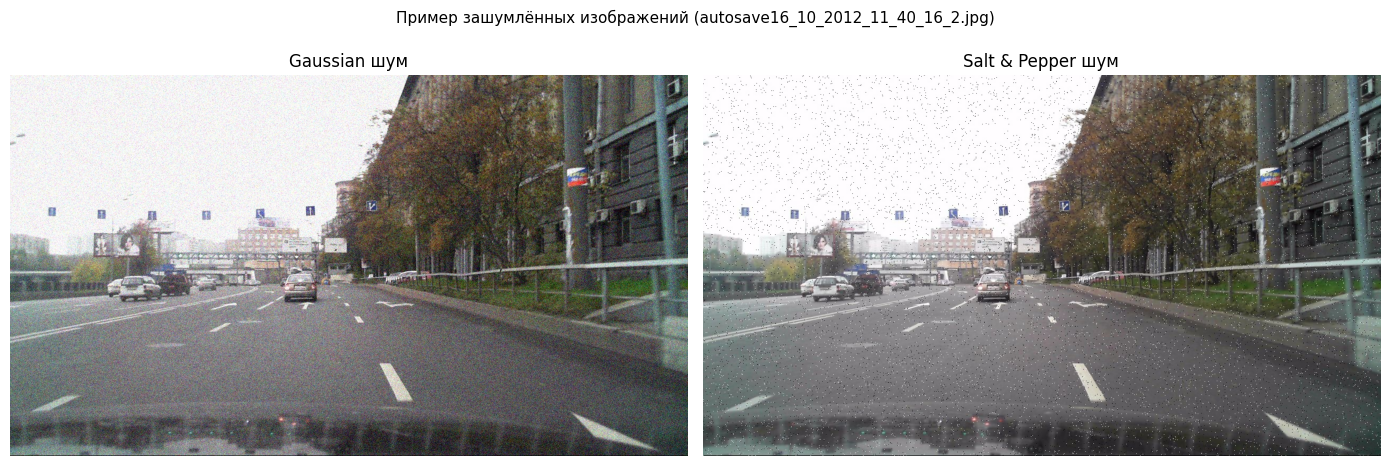

Изображение: autosave16_10_2012_11_40_16_2.jpg


In [5]:
import cv2
import matplotlib.pyplot as plt
import os
import random
OUTPUT_DIR = 'rtsd_yolo'
# Берём случайные картинки из папок с зашумлёнными изображениями
gaussian_dir    = os.path.join(OUTPUT_DIR, 'images', 'test_gaussian')
saltpepper_dir  = os.path.join(OUTPUT_DIR, 'images', 'test_salt_pepper')

# Выбираем случайную картинку
files = os.listdir(gaussian_dir)

fname = random.choice(files)

img_gaussian   = cv2.imread(os.path.join(gaussian_dir, fname))
img_saltpepper = cv2.imread(os.path.join(saltpepper_dir, fname))

img_gaussian   = cv2.cvtColor(img_gaussian,   cv2.COLOR_BGR2RGB)
img_saltpepper = cv2.cvtColor(img_saltpepper, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(img_gaussian)
axes[0].set_title('Gaussian шум', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img_saltpepper)
axes[1].set_title('Salt & Pepper шум', fontsize=12)
axes[1].axis('off')

plt.suptitle(f'Пример зашумлённых изображений ({fname})', fontsize=11)
plt.tight_layout()
plt.savefig('noise_examples.png', dpi=150)
plt.show()
print(f'Изображение: {fname}')

## 3. Настройки путей

In [4]:
import os

# === УКАЖИ ПУТЬ К ДАТАСЕТУ ===
DATASET_ROOT = 'rtsd_data'

TRAIN_ANNO  = os.path.join(DATASET_ROOT, 'train_anno.json')
VAL_ANNO    = os.path.join(DATASET_ROOT, 'val_anno.json')
LABEL_MAP   = os.path.join(DATASET_ROOT, 'label_map.json')
FRAMES_DIR  = os.path.join(DATASET_ROOT, 'rtsd-frames', 'rtsd-frames')

# Параметры обучения
TOP_N                = 30
MAX_IMAGES_PER_CLASS = 1000
BATCH_SIZE           = 8
NUM_EPOCHS           = 15
IMG_SIZE             = 640
LR                   = 0.005
MODEL_NAME           = 'yolov8n.pt'   # nano; меняй на yolov8s/m по желанию

YOLO_DATASET_DIR = 'rtsd_yolo'        # сюда запишем датасет в формате YOLO

print("Пути настроены для Google Colab.")
print(f"Папка с данными:   {DATASET_ROOT}")
print(f"Существует ли папка с кадрами: {os.path.exists(FRAMES_DIR)}")


Пути настроены для Google Colab.
Папка с данными:   rtsd_data
Существует ли папка с кадрами: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


## 4. Анализ датасета и фильтрация редких классов

Train: 54188 изображений, 95518 объектов
Val:   5000 изображений, 8866 объектов
Классов в label_map: 155

Всего классов в train: 155
Макс объектов в классе: 22155
Мин объектов в классе:  1

Топ-30 классов: [1, 2, 3, 4, 5, 6, 7, 8, 10, 13, 15, 17, 22, 23, 25, 26, 32, 33, 35, 40, 41, 43, 47, 52, 54, 55, 63, 69, 71, 82]
NUM_CLASSES: 30

После балансировки (макс 1000 картинок на класс):
Train: 24028 изображений, 42820 объектов


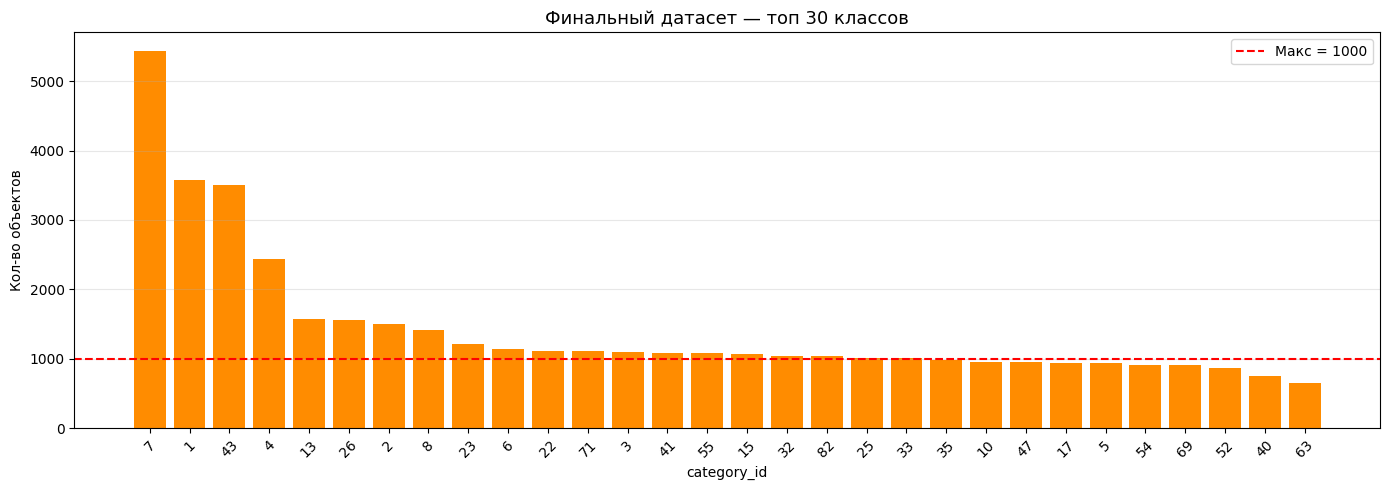

In [5]:
# Загружаем аннотации
with open(TRAIN_ANNO, 'r') as f:
    train_data = json.load(f)

with open(VAL_ANNO, 'r') as f:
    val_data = json.load(f)

with open(LABEL_MAP, 'r') as f:
    label_map = json.load(f)

print(f"Train: {len(train_data['images'])} изображений, {len(train_data['annotations'])} объектов")
print(f"Val:   {len(val_data['images'])} изображений, {len(val_data['annotations'])} объектов")
print(f"Классов в label_map: {len(label_map)}")

# Подсчёт классов
class_counts = Counter()
for ann in train_data['annotations']:
    class_counts[ann['category_id']] += 1

print(f"\nВсего классов в train: {len(class_counts)}")
print(f"Макс объектов в классе: {max(class_counts.values())}")
print(f"Мин объектов в классе:  {min(class_counts.values())}")

# Топ-30 классов
top_classes   = {cat_id for cat_id, _ in class_counts.most_common(TOP_N)}
# YOLO требует label 0..N-1 (без фона)
cat_id_to_new = {old: new for new, old in enumerate(sorted(top_classes))}
new_to_cat_id = {v: k for k, v in cat_id_to_new.items()}
NUM_CLASSES   = len(top_classes)
print(f"\nТоп-{TOP_N} классов: {sorted(top_classes)}")
print(f"NUM_CLASSES: {NUM_CLASSES}")

# Фильтруем аннотации
train_anns_filtered = [a for a in train_data['annotations'] if a['category_id'] in top_classes]
train_img_ids       = {a['image_id'] for a in train_anns_filtered}
train_imgs_filtered = [img for img in train_data['images'] if img['id'] in train_img_ids]

# Балансировка — максимум MAX_IMAGES_PER_CLASS картинок на класс
cat_to_imgs = defaultdict(list)
for ann in train_anns_filtered:
    cat_to_imgs[ann['category_id']].append(ann['image_id'])

imgs_to_keep = set()
for cat_id, img_ids in cat_to_imgs.items():
    unique_imgs = list(dict.fromkeys(img_ids))
    imgs_to_keep.update(unique_imgs[:MAX_IMAGES_PER_CLASS])

train_imgs_filtered = [img for img in train_imgs_filtered if img['id'] in imgs_to_keep]
train_anns_filtered = [a   for a   in train_anns_filtered if a['image_id'] in imgs_to_keep]

print(f"\nПосле балансировки (макс {MAX_IMAGES_PER_CLASS} картинок на класс):")
print(f"Train: {len(train_imgs_filtered)} изображений, {len(train_anns_filtered)} объектов")

# Гистограмма
class_counts_final = Counter(ann['category_id'] for ann in train_anns_filtered)
sorted_final = sorted(class_counts_final.items(), key=lambda x: -x[1])

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar([str(x[0]) for x in sorted_final], [x[1] for x in sorted_final], color='darkorange')
ax.axhline(y=MAX_IMAGES_PER_CLASS, color='red', linestyle='--', label=f'Макс = {MAX_IMAGES_PER_CLASS}')
ax.set_title(f'Финальный датасет — топ {TOP_N} классов', fontsize=13)
ax.set_xlabel('category_id')
ax.set_ylabel('Кол-во объектов')
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('class_distribution_final.png', dpi=100)
plt.show()


## 5. Конвертация датасета в формат YOLO

YOLO ожидает структуру:
```
rtsd_yolo/
  images/train/  images/val/  images/test/
  labels/train/  labels/val/  labels/test/
```
Для каждого изображения — `.txt` с аннотациями: `class cx cy w h` (нормализованные 0..1).

In [7]:
import shutil

def write_yolo_labels(imgs_list, anns_list, frames_dir, img_out_dir, lbl_out_dir, cat_id_to_new):
    """
    Копирует изображения и создаёт YOLO-метки.
    COCO bbox [x,y,w,h] -> YOLO [cx,cy,w,h] нормализованные.
    """
    os.makedirs(img_out_dir, exist_ok=True)
    os.makedirs(lbl_out_dir, exist_ok=True)

    # Группируем аннотации по image_id
    ann_by_img = defaultdict(list)
    for ann in anns_list:
        ann_by_img[ann['image_id']].append(ann)

    copied = 0
    for img_info in imgs_list:
        img_id   = img_info['id']
        fname    = os.path.basename(img_info['file_name'])
        src_path = os.path.join(frames_dir, fname)
        dst_img  = os.path.join(img_out_dir, fname)
        dst_lbl  = os.path.join(lbl_out_dir, os.path.splitext(fname)[0] + '.txt')

        if not os.path.exists(src_path):
            continue

        # Получаем размер изображения
        W, H = img_info['width'], img_info['height']

        lines = []
        for ann in ann_by_img[img_id]:
            new_cls = cat_id_to_new.get(ann['category_id'])
            if new_cls is None:
                continue
            x, y, w, h = ann['bbox']
            if w <= 0 or h <= 0:
                continue
            # YOLO: центр + ширина/высота, нормализованные
            cx = (x + w / 2) / W
            cy = (y + h / 2) / H
            nw = w / W
            nh = h / H
            lines.append(f"{new_cls} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")

        if not lines:
            continue  # пропускаем изображения без объектов нужных классов

        shutil.copy2(src_path, dst_img)
        with open(dst_lbl, 'w') as f:
            f.write('\n'.join(lines))
        copied += 1

    return copied


# Сплит 70 / 15 / 15 (те же пропорции что в Faster R-CNN ноутбуке)
random.seed(42)
all_imgs = train_imgs_filtered.copy()
random.shuffle(all_imgs)

n_test = int(len(all_imgs) * 0.15)
n_val  = int(len(all_imgs) * 0.15)

test_imgs_split  = all_imgs[:n_test]
val_imgs_split   = all_imgs[n_test : n_test + n_val]
train_imgs_split = all_imgs[n_test + n_val:]

print(f"Train: {len(train_imgs_split)} | Val: {len(val_imgs_split)} | Test: {len(test_imgs_split)}")

# Аннотации для каждого split
train_ids = {img['id'] for img in train_imgs_split}
val_ids   = {img['id'] for img in val_imgs_split}
test_ids  = {img['id'] for img in test_imgs_split}

train_anns_split = [a for a in train_anns_filtered if a['image_id'] in train_ids]
val_anns_split   = [a for a in train_anns_filtered if a['image_id'] in val_ids]
test_anns_split  = [a for a in train_anns_filtered if a['image_id'] in test_ids]

# Запись файлов
for split, imgs, anns in [
    ('train', train_imgs_split, train_anns_split),
    ('val',   val_imgs_split,   val_anns_split),
    ('test',  test_imgs_split,  test_anns_split),
]:
    n = write_yolo_labels(
        imgs, anns, FRAMES_DIR,
        img_out_dir=f'{YOLO_DATASET_DIR}/images/{split}',
        lbl_out_dir=f'{YOLO_DATASET_DIR}/labels/{split}',
        cat_id_to_new=cat_id_to_new,
    )
    print(f"{split}: записано {n} изображений")


Train: 16820 | Val: 3604 | Test: 3604


train: записано 16820 изображений
val: записано 3604 изображений
test: записано 3604 изображений


## 6. Создание YAML-конфига для Ultralytics

In [8]:
import yaml

# Названия классов: используем оригинальный category_id как строку
# (или можно взять из label_map если он содержит читаемые имена)
class_names = {new_id: str(old_id) for old_id, new_id in cat_id_to_new.items()}
names_list  = [class_names[i] for i in range(NUM_CLASSES)]

dataset_yaml = {
    'path':  os.path.abspath(YOLO_DATASET_DIR),
    'train': 'images/train',
    'val':   'images/val',
    'test':  'images/test',
    'nc':    NUM_CLASSES,
    'names': names_list,
}

yaml_path = os.path.join(YOLO_DATASET_DIR, 'dataset.yaml')
with open(yaml_path, 'w') as f:
    yaml.dump(dataset_yaml, f, allow_unicode=True, default_flow_style=False)

print(f"YAML сохранён: {yaml_path}")
print(f"nc = {NUM_CLASSES}")
print(f"Классы: {names_list}")


YAML сохранён: rtsd_yolo/dataset.yaml
nc = 30
Классы: ['1', '2', '3', '4', '5', '6', '7', '8', '10', '13', '15', '17', '22', '23', '25', '26', '32', '33', '35', '40', '41', '43', '47', '52', '54', '55', '63', '69', '71', '82']


## 7. Проверка датасета — визуализация примера

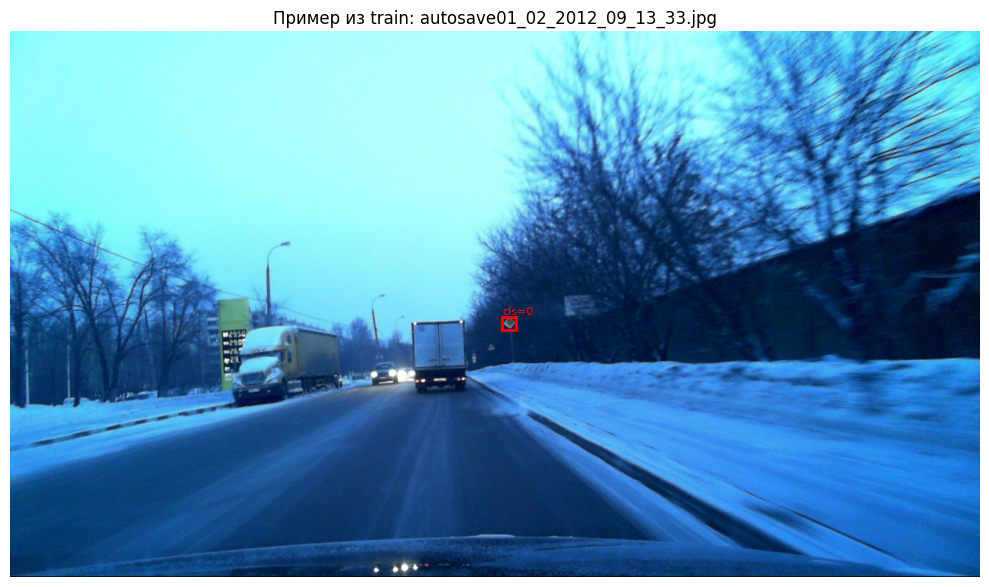

In [9]:
import glob

# Берём первое изображение из train
sample_imgs = sorted(glob.glob(f'{YOLO_DATASET_DIR}/images/train/*.jpg'))[:1]
if not sample_imgs:
    sample_imgs = sorted(glob.glob(f'{YOLO_DATASET_DIR}/images/train/*.png'))[:1]

img_path = sample_imgs[0]
lbl_path = img_path.replace('images', 'labels').rsplit('.', 1)[0] + '.txt'

img = Image.open(img_path)
W, H = img.size

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(img)

with open(lbl_path) as f:
    for line in f:
        cls, cx, cy, nw, nh = map(float, line.split())
        x1 = (cx - nw/2) * W
        y1 = (cy - nh/2) * H
        bw = nw * W
        bh = nh * H
        rect = patches.Rectangle((x1, y1), bw, bh,
                                   linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        ax.text(x1, y1-4, f'cls={int(cls)}', color='red', fontsize=8)

ax.set_title(f"Пример из train: {os.path.basename(img_path)}")
ax.axis('off')
plt.tight_layout()
plt.show()


## 8. Модель — YOLOv8 с pretrained весами COCO

Ultralytics автоматически скачивает pretrained веса и заменяет голову под `nc` классов.

In [10]:
# Загружаем pretrained YOLOv8 (веса COCO)
model = YOLO(MODEL_NAME)

print(f"Модель: {MODEL_NAME}")
print(f"NUM_CLASSES: {NUM_CLASSES}")


Модель: yolov8n.pt
NUM_CLASSES: 30


## 9. Обучение

In [11]:
results = model.train(
    data      = yaml_path,
    epochs    = NUM_EPOCHS,
    imgsz     = IMG_SIZE,
    batch     = BATCH_SIZE,
    lr0       = LR,
    momentum  = 0.9,
    weight_decay = 0.0005,
    device    = device,
    project   = 'runs/rtsd',
    name      = 'yolov8_rtsd',
    exist_ok  = True,
    # Полные метрики включены по умолчанию:
    # mAP@0.5, mAP@0.5:0.95, precision, recall
    plots     = True,    # сохраняет графики потерь и метрик
    save      = True,    # сохраняет best.pt и last.pt
    verbose   = True,
)

print("\nОбучение завершено!")
print(f"Лучшая модель: runs/rtsd/yolov8_rtsd/weights/best.pt")


Ultralytics 8.4.57 🚀 Python-3.12.3 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX 4000 SFF Ada Generation, 20019MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=rtsd_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=yolov8_rtsd, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=T

## 10. Финальная оценка на test — все метрики

In [13]:
# Загружаем лучшую модель
best_model = YOLO('runs/detect/runs/rtsd/yolov8_rtsd/weights/best.pt')

# Оценка на test
test_metrics = best_model.val(
    data   = yaml_path,
    split  = 'test',
    imgsz  = IMG_SIZE,
    device = device,
    plots  = True,
    save_json = True,   # сохраняет predictions.json для COCO evaluate
)

print("\nМетрики на TEST:")
print(f"  mAP@0.50:0.95 : {test_metrics.box.map:.4f}")
print(f"  mAP@0.50      : {test_metrics.box.map50:.4f}")
print(f"  mAP@0.75      : {test_metrics.box.map75:.4f}")
print(f"  Precision     : {test_metrics.box.mp:.4f}")
print(f"  Recall        : {test_metrics.box.mr:.4f}")
print(f"\nPer-class AP50: {test_metrics.box.ap50}")


Ultralytics 8.4.57 🚀 Python-3.12.3 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX 4000 SFF Ada Generation, 20019MiB)
Model summary (fused): 73 layers, 3,011,498 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 504.3±388.9 MB/s, size: 149.2 KB)
val: Scanning /home/minvalieva/projects/rtsd_yolo/labels/test... 436 images, 0 backgrounds, 0 corrupt: 12% ━─────────── 436/3604 1.3Kit/s 0.1s<2.4s

val: Scanning /home/minvalieva/projects/rtsd_yolo/labels/test... 3604 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3604/3604 4.7Kit/s 0.8s0.1s
val: New cache created: /home/minvalieva/projects/rtsd_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 226/226 4.2it/s 53.7s<0.2s
                   all       3604       6425      0.848        0.8      0.876      0.622
                     1        550        554      0.932      0.887      0.953      0.695
                     2        217        221      0.875      0.855      0.922      0.687
                     3        155        173       0.83      0.775      0.854      0.595
                     4        344        390       0.88      0.769      0.873       0.61
                     5        140        142      0.773      0.792      0.836      0.546
                     6        164        179      0.838      0.754       0.86      0.627
              

## 11. Графики потерь и метрик

Ultralytics автоматически сохраняет все графики в папку `runs/rtsd/yolov8_rtsd/`.
Ниже — отображение уже готовых графиков.

In [ ]:
from IPython.display import Image as IPImage, display

plots_dir = 'runs/rtsd/yolov8_rtsd'
for plot_name in ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png']:
    plot_path = os.path.join(plots_dir, plot_name)
    if os.path.exists(plot_path):
        print(f"\n{plot_name}:")
        display(IPImage(plot_path))
    else:
        print(f"{plot_name} не найден — возможно, другой путь")


## 12. Сохранение истории обучения

In [ ]:
import pandas as pd

# Ultralytics сохраняет историю в CSV
results_csv = 'runs/rtsd/yolov8_rtsd/results.csv'
if os.path.exists(results_csv):
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()
    print("Колонки истории:", df.columns.tolist())
    print(df.tail())

    # Дополнительно сохраняем в pickle для совместимости
    history = df.to_dict(orient='list')
    with open('history_rtsd_yolo.pickle', 'wb') as f:
        pickle.dump(history, f)
    print("\nИстория сохранена в history_rtsd_yolo.pickle")

# Сохраняем маппинг классов
with open('cat_id_to_new_yolo.json', 'w') as f:
    json.dump({str(k): v for k, v in cat_id_to_new.items()}, f)

print("Маппинг классов сохранён в cat_id_to_new_yolo.json")
print(f"Лучшая модель: runs/rtsd/yolov8_rtsd/weights/best.pt")


## 13. Инференс — визуализация предсказаний

In [ ]:
import glob

def predict_and_show(model, img_path, gt_boxes_xywh, gt_labels,
                     device='cuda', threshold=0.5, nms_iou=0.3, cat_id_to_new=None):
    """
    Показывает Ground Truth (слева) и предсказания YOLOv8 (справа).
    gt_boxes_xywh — COCO-формат [x,y,w,h] в пикселях.
    """
    model.overrides['conf'] = threshold
    model.overrides['iou']  = nms_iou

    results = model.predict(img_path, device=device, verbose=False)[0]

    img = Image.open(img_path)
    W, H = img.size
    img_np = np.array(img)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- Ground Truth ---
    axes[0].imshow(img_np)
    new_to_cat = {v: k for k, v in cat_id_to_new.items()} if cat_id_to_new else {}
    for (x, y, w, h), lbl in zip(gt_boxes_xywh, gt_labels):
        rect = patches.Rectangle((x, y), w, h,
                                   linewidth=2, edgecolor='green', facecolor='none')
        axes[0].add_patch(rect)
        orig = new_to_cat.get(lbl, lbl)
        axes[0].text(x, y-4, str(orig), color='green', fontsize=7)
    axes[0].set_title('Ground Truth')
    axes[0].axis('off')

    # --- Предсказания ---
    axes[1].imshow(img_np)
    boxes  = results.boxes.xyxy.cpu().numpy()
    scores = results.boxes.conf.cpu().numpy()
    labels = results.boxes.cls.cpu().numpy().astype(int)
    for (x1, y1, x2, y2), score, lbl in zip(boxes, scores, labels):
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                   linewidth=2, edgecolor='red', facecolor='none')
        axes[1].add_patch(rect)
        orig = new_to_cat.get(lbl, lbl)
        axes[1].text(x1, y1-4, f'{orig}:{score:.2f}', color='red', fontsize=7)
    axes[1].set_title(f'YOLOv8 (conf={threshold}) | найдено: {len(boxes)}')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()


# Подготовим данные для нескольких примеров из test
ann_by_img = defaultdict(list)
for ann in test_anns_split:
    ann_by_img[ann['image_id']].append(ann)

sample_indices = [0, 10, 50, 100]

for idx in sample_indices:
    if idx >= len(test_imgs_split):
        continue
    img_info = test_imgs_split[idx]
    fname    = os.path.basename(img_info['file_name'])
    img_path = os.path.join(YOLO_DATASET_DIR, 'images', 'test', fname)
    if not os.path.exists(img_path):
        continue

    anns = ann_by_img[img_info['id']]
    gt_boxes  = [[a['bbox'][0], a['bbox'][1], a['bbox'][2], a['bbox'][3]] for a in anns
                  if a['category_id'] in top_classes]
    gt_labels = [cat_id_to_new[a['category_id']] for a in anns
                  if a['category_id'] in top_classes]

    print(f"\nПример {idx}: {fname}")
    predict_and_show(best_model, img_path, gt_boxes, gt_labels,
                     device=device, threshold=0.5, cat_id_to_new=cat_id_to_new)


## 14. Загрузка сохранённой модели

In [ ]:
def load_model(model_path, device='cuda'):
    """Загружает YOLOv8 модель из .pt файла."""
    m = YOLO(model_path)
    m.to(device)
    return m

# Пример:
# model_loaded = load_model('runs/rtsd/yolov8_rtsd/weights/best.pt')
# results = model_loaded.predict('path/to/image.jpg', conf=0.5)
print("Функция load_model готова.")
print(f"NUM_CLASSES = {NUM_CLASSES}")
